# BTCUSDT 4h - ML training, benchmarking & testing
Implements the spec: dynamic S/R levels -> stationary features -> triple-barrier labels -> purged walk-forward LightGBM (long & short models) -> Optuna tuning on pre-test data -> benchmarks (Buy&Hold, random entries, Donchian, always-long, logistic regression) -> sealed hold-out + leakage tests.

**Needs:** `crypto_data/4h/BTCUSDT_4h.parquet` in Drive (from the downloader notebooks). Higher-timeframe files (if present) are used automatically for confluence, gating and zone rules.

**Not financial advice.** Results are research output; costs, slippage and regime change can make live results differ.

## 1. Install & mount Drive

In [1]:
!pip install -q lightgbm optuna scikit-learn pyarrow matplotlib scipy joblib catboost numba



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False
    print("Running in local environment (Google Colab drive mount skipped).")

Running in local environment (Google Colab drive mount skipped).


## 2. Config

In [3]:
import os
# ============ CONFIG (edit here) ============
TF      = "4h"
SYMBOL  = "BTCUSDT"
DEF_DATA   = "/content/drive/MyDrive/crypto_data" if ("IN_COLAB" in globals() and IN_COLAB) else r"D:\Projects_Main\Trade-Pro\Trader-Pro\notebooks\data"
DEF_MODEL  = "/content/drive/MyDrive/crypto_models" if ("IN_COLAB" in globals() and IN_COLAB) else r"D:\Projects_Main\Trade-Pro\Trader-Pro\notebooks\model"
DATA_ROOT  = os.environ.get("DATA_ROOT", DEF_DATA)     # data folder: D:\Projects_Main\Trade-Pro\Trader-Pro\notebooks\data
MODEL_ROOT = os.environ.get("MODEL_ROOT", DEF_MODEL)   # model folder: D:\Projects_Main\Trade-Pro\Trader-Pro\notebooks\model

# ---- Triple-barrier labels (spec section 6) ----
TP_ATR, SL_ATR = 3.0, 1.0          # +3.0 x ATR take-profit (1:3 R:R for fat-tail runs), -1.0 x ATR stop

# ---- Execution assumptions (realistic costs matter a lot on low timeframes) ----
FEE_SIDE   = 0.0002                # 0.02% maker fee per side (post-only execution)
SLIP_SIDE  = 0.0001                # 0.01% slippage per side
RISK_PCT   = 0.01                  # risk 1% of equity per trade (1R = 1 x ATR stop)
MAX_LEV    = 3.0                   # cap on notional leverage

# ---- Testing protocol ----
HOLDOUT_MONTHS = 6                 # last N months = sealed hold-out (judge it ONCE, do not tune on it)
RANDOM_RUNS    = 300               # random-entry benchmark simulations
APPLY_RULES    = False             # False = disable counter-productive static S/R zone filtering
HIGH_CONVICTION_PCT = 0.85         # execute top 15% highest conviction signals to eliminate fee churn
ZONE_TOL_ATR   = 1.0               # price counts as "tapped a level" if within this many ATR
CONF_TOL       = 0.0035            # 0.35% multi-timeframe confluence window (spec)
USE_UNIQUENESS_WEIGHTS = True
SEED = 42

# ---- Per-timeframe settings (bar counts from the spec table; horizon/train windows are my choices) ----
TF_CFG = {
 "15m": dict(delta="15min", pivot_k=3, lookback=144, cap=3, inval_atr=0.0, far_atr=None, single_use=True,
             horizon=24, train_m=24, test_m=3, min_trades=100, n_trials=40,
             htfs=["1h","4h","1d","1w"], zone_src=["4h","1d"], gate_src=["4h","1d","1w"]),
 "1h":  dict(delta="1h",   pivot_k=4, lookback=125, cap=5, inval_atr=0.0, far_atr=3.0, single_use=False,
             horizon=24, train_m=24, test_m=3, min_trades=60, n_trials=40,
             htfs=["4h","1d","1w"], zone_src=["4h","1d"], gate_src=["4h","1d","1w"]),
 "4h":  dict(delta="4h",   pivot_k=5, lookback=215, cap=7, inval_atr=0.0, far_atr=4.0, single_use=False,
             horizon=6,  train_m=24, test_m=3, min_trades=40, n_trials=50,
             htfs=["1d","1w"], zone_src=["own","1d"], gate_src=["1d","1w"]),
 "1d":  dict(delta="1D",   pivot_k=5, lookback=270, cap=6, inval_atr=0.0, far_atr=None, single_use=False,
             horizon=6,  train_m=24, test_m=3, min_trades=25, n_trials=50,
             htfs=["1w"], zone_src=["own"], gate_src=["1w"]),
 "1w":  dict(delta="7D",   pivot_k=3, lookback=125, cap=4, inval_atr=2.0, far_atr=None, single_use=False,
             horizon=4,  train_m=36, test_m=6, min_trades=10, n_trials=30,
             htfs=[], zone_src=["own"], gate_src=[]),
}

# ---- Small-data regularisation: tighter trees / fewer rounds where there are few samples ----
#   depth = (min,max) tree depth searched by Optuna | mcs = (min,max) min_child_samples | nest = (min,max) n_estimators
#   default_mcs = fallback min_child_samples if tuning finds too few trades
REG = {
 "15m": dict(depth=(2, 6), mcs=(20, 300), nest=(100, 500), default_mcs=100),
 "1h":  dict(depth=(2, 6), mcs=(20, 300), nest=(100, 500), default_mcs=100),
 "4h":  dict(depth=(2, 6), mcs=(20, 300), nest=(100, 500), default_mcs=100),
 "1d":  dict(depth=(2, 4), mcs=(15, 150), nest=(100, 400), default_mcs=50),
 "1w":  dict(depth=(2, 4), mcs=(5, 40),   nest=(50, 300),  default_mcs=15),   # ~150 train rows per fold -> min_child_samples must be small
}

# ---- Feature trimming: redundant features removed where data is small (S/R, RSI, MACD, EMA50, volume z-score are kept) ----
_DROP = {
 "1w": ["ret_3", "ret_12", "range_pct", "body_pct", "bb_width", "ema_dist_20", "ema20_slope",
        "taker_ratio", "vol_ratio", "dsup_own", "dres_own"],
 "1d": ["ret_3", "ret_12", "range_pct", "bb_width", "ema_dist_20", "ema20_slope", "dsup_own", "dres_own"],
}
DROP_FEATURES = _DROP.get(TF, [])

# ---- Expected-move model (regression; sits next to the TP-first classifiers) ----
RUN_MOVE_MODEL = True              # predict how far price is likely to travel (in ATR units) within H bars
MOVE_CLIP      = 6.0               # targets are clipped at +-6 ATR so a handful of extreme bars can't dominate

# ---- Extras ----
RUN_MODEL_COMPARISON = True        # compare LightGBM vs CatBoost vs ExtraTrees vs LogReg on the SAME folds (AUC)
SAVE_VERSIONED = True              # also keep a time-stamped copy of the final model in Drive
# ==============================================
# Breakeven & High-Win-Rate Settings (Kaminski & Lo, 2014)
BE_TRIGGER_ATR = 0.8                   # ratchet SL to breakeven once price reaches +0.8 ATR
BE_SL_ATR      = 0.05                  # ratcheted SL level (+0.05 ATR covers round-trip exchange fees)

# ==============================================================================
# FAST ANALYTICS MODE: ONLY_ANALYTICS
# Set ONLY_ANALYTICS = True to run full analytics, benchmarks, plots & signals in ~5s!
# (Skips heavy Optuna tuning & walk-forward retraining; loads saved models & OOS from disk)
# Set ONLY_ANALYTICS = False when you want to retrain models from scratch.
# ==============================================================================
ONLY_ANALYTICS = True


## 3. Load data

In [4]:
import os, json, math, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import optuna, joblib
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from IPython.display import display

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
np.random.seed(SEED)

CFG   = TF_CFG[TF]
H     = CFG["horizon"]
DELTA = pd.Timedelta(CFG["delta"])
COST_SIDE = FEE_SIDE + SLIP_SIDE
OUT_DIR = os.path.join(MODEL_ROOT, TF)
os.makedirs(OUT_DIR, exist_ok=True)

def to_ns(s):
    return pd.to_datetime(s, utc=True).astype("datetime64[ns, UTC]")

def load_tf(tf):
    p = os.path.join(DATA_ROOT, tf, f"{SYMBOL}_{tf}.parquet")
    if not os.path.exists(p):
        return None
    d = pd.read_parquet(p).sort_values("open_time").drop_duplicates("open_time").reset_index(drop=True)
    d["open_time"]  = to_ns(d["open_time"])
    d["close_time"] = to_ns(d["close_time"])
    return d

df = load_tf(TF)
assert df is not None, f"Data file not found: {DATA_ROOT}/{TF}/{SYMBOL}_{TF}.parquet - run the downloader notebook first."
T_BAR = pd.DatetimeIndex(df["open_time"])
print(f"{SYMBOL} {TF}: {len(df):,} bars  {T_BAR[0]}  ->  {T_BAR[-1]}")
print("Output folder:", OUT_DIR)

BTCUSDT 4h: 14,947 bars  2020-01-01 00:00:00+00:00  ->  2026-10-27 00:00:00+00:00
Output folder: D:\Projects_Main\Trade-Pro\Trader-Pro\notebooks\model\4h


D:\Projects_Main\Trade-Pro\Trader-Pro\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 4. Indicators, level engine & features
Stationary features only (returns, ATR-normalised distances, flags). Levels use bar-count lookbacks / caps / invalidation from the spec table; higher-timeframe context is merged *as-of the last completed HTF bar*.

In [5]:
# ---------- indicators (all causal: use only data up to the current bar) ----------
def ema(s, n):
    return s.ewm(span=n, adjust=False, min_periods=n).mean()

def atr_wilder(d, n=14):
    pc = d["close"].shift(1)
    tr = pd.concat([d["high"] - d["low"], (d["high"] - pc).abs(), (d["low"] - pc).abs()], axis=1).max(axis=1)
    return tr.ewm(alpha=1/n, adjust=False, min_periods=n).mean()

def rsi(c, n=14):
    dlt = c.diff()
    up, dn = dlt.clip(lower=0), -dlt.clip(upper=0)
    ru = up.ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    rd = dn.ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    return 100 - 100 / (1 + ru / rd.replace(0, np.nan))

In [6]:
# ---------- dynamic support/resistance engine (spec sections 1-2) ----------
def build_levels(d, cfg):
    """Swing-pivot levels with: bar-count lookback, max-active cap, invalidation, distance pruning, single-use (15m).
    A pivot is only added k bars AFTER it forms (when it is confirmed) -> no look-ahead."""
    k, cap = cfg["pivot_k"], cfg["cap"]
    n = len(d)
    hi, lo, cl = d["high"].values, d["low"].values, d["close"].values
    at = atr_wilder(d).values
    w = 2 * k + 1
    ph = (d["high"].rolling(w, center=True).max() == d["high"]).values
    pl = (d["low"].rolling(w, center=True).min() == d["low"]).values
    side_cap = max(1, math.ceil(cap / 2))
    sup, res = [], []                       # level = [price, pivot_idx, touches]
    out = np.full((n, 10), np.nan)
    for i in range(n):
        a = at[i]
        if np.isnan(a):
            continue
        j = i - k
        if j >= 0:
            if pl[j] and not any(abs(L[0] - lo[j]) < 0.25 * a for L in sup):
                sup.append([lo[j], j, 0])
            if ph[j] and not any(abs(L[0] - hi[j]) < 0.25 * a for L in res):
                res.append([hi[j], j, 0])
        ev_s = ev_r = 0.0
        keep = []
        for L in sup:
            p, j0, _ = L
            if cl[i] < p - cfg["inval_atr"] * a: continue            # broken
            if i - j0 > cfg["lookback"]: continue                    # too old
            if cfg["far_atr"] and abs(cl[i] - p) > cfg["far_atr"] * a: continue
            if lo[i] <= p + 0.1 * a:                                  # touched
                ev_s = 1.0
                if cfg["single_use"]: continue                        # purge on 1st touch
                L[2] += 1
            keep.append(L)
        sup = sorted(keep, key=lambda L: -L[1])[:side_cap]
        keep = []
        for L in res:
            p, j0, _ = L
            if cl[i] > p + cfg["inval_atr"] * a: continue
            if i - j0 > cfg["lookback"]: continue
            if cfg["far_atr"] and abs(cl[i] - p) > cfg["far_atr"] * a: continue
            if hi[i] >= p - 0.1 * a:
                ev_r = 1.0
                if cfg["single_use"]: continue
                L[2] += 1
            keep.append(L)
        res = sorted(keep, key=lambda L: -L[1])[:side_cap]
        below = [L for L in sup if L[0] <= cl[i]]
        above = [L for L in res if L[0] >= cl[i]]
        row = [np.nan] * 6
        if below:
            s = max(below, key=lambda L: L[0]); row[0], row[1], row[2] = s[0], i - s[1], s[2]
        if above:
            r = min(above, key=lambda L: L[0]); row[3], row[4], row[5] = r[0], i - r[1], r[2]
        out[i] = row + [len(sup), len(res), ev_s, ev_r]
    return pd.DataFrame(out, columns=["sup_px","sup_age","sup_touch","res_px","res_age","res_touch",
                                      "n_sup","n_res","ev_sup","ev_res"], index=d.index)

In [7]:
# ---------- stationary features (spec section 4) ----------
def own_features(d, cfg, tf):
    c = d["close"]; lc = np.log(c)
    F = pd.DataFrame(index=d.index)
    for n in (1, 3, 6, 12, 24):
        F[f"ret_{n}"] = lc.diff(n)
    at = atr_wilder(d)
    F["atr_pct"]   = at / c
    F["atr_ratio"] = at / at.rolling(50).mean()
    F["range_pct"] = (d["high"] - d["low"]) / c
    F["body_pct"]  = (c - d["open"]) / c
    rng = (d["high"] - d["low"]).replace(0, np.nan)
    F["upper_wick"] = (d["high"] - np.maximum(d["open"], c)) / rng
    F["lower_wick"] = (np.minimum(d["open"], c) - d["low"]) / rng
    F["rsi14"] = rsi(c)
    macd = ema(c, 12) - ema(c, 26)
    F["macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()) / c
    ma, sd = c.rolling(20).mean(), c.rolling(20).std()
    F["bb_pctb"]  = (c - (ma - 2 * sd)) / (4 * sd)
    F["bb_width"] = 4 * sd / ma
    for n in (20, 50):
        F[f"ema_dist_{n}"] = (c - ema(c, n)) / c
    F["ema_20_50"]  = (ema(c, 20) - ema(c, 50)) / c
    F["ema20_slope"] = ema(c, 20).pct_change(5)
    lv = np.log1p(d["volume"])
    F["vol_z"] = (lv - lv.rolling(50).mean()) / lv.rolling(50).std()
    F["taker_ratio"] = (d["taker_buy_base"] / d["volume"].replace(0, np.nan)).fillna(0.5)
    r1 = lc.diff()
    F["vol_ratio"] = r1.rolling(20).std() / r1.rolling(50).std()
    if tf in ("15m", "1h", "4h"):
        h = d["open_time"].dt.hour + d["open_time"].dt.minute / 60
        F["hour_sin"], F["hour_cos"] = np.sin(2*np.pi*h/24), np.cos(2*np.pi*h/24)
    if tf in ("15m", "1h", "4h", "1d"):
        dw = d["open_time"].dt.dayofweek
        F["dow_sin"], F["dow_cos"] = np.sin(2*np.pi*dw/7), np.cos(2*np.pi*dw/7)
    lev = build_levels(d, cfg)
    F["dsup_own"] = (c - lev["sup_px"]) / c
    F["dres_own"] = (lev["res_px"] - c) / c
    F["dsup_atr"] = (c - lev["sup_px"]) / at
    F["dres_atr"] = (lev["res_px"] - c) / at
    for col in ["sup_age","res_age","sup_touch","res_touch","n_sup","n_res","ev_sup","ev_res"]:
        F[col] = lev[col]
    aux = pd.DataFrame({"sup_own": lev["sup_px"].values, "res_own": lev["res_px"].values}, index=d.index)
    return F, aux, at

def htf_table(tf):
    h = load_tf(tf)
    if h is None:
        return None
    lv = build_levels(h, TF_CFG[tf])
    return pd.DataFrame({"close_time": to_ns(h["close_time"]),
                         "sup_px": lv["sup_px"].values, "res_px": lv["res_px"].values,
                         "trend": np.sign(h["close"] - ema(h["close"], 50)).values})

def build_all(d, cfg, tf, use_htf=True):
    F, aux, at = own_features(d, cfg, tf)
    c = d["close"].values
    sup_own, res_own = aux["sup_own"].values, aux["res_own"].values
    conf_s = (~np.isnan(sup_own)).astype(float)
    conf_r = (~np.isnan(res_own)).astype(float)
    trends, sup_cols, res_cols, loaded = {}, {"own": sup_own}, {"own": res_own}, []
    if use_htf:
        left = pd.DataFrame({"ct": to_ns(d["close_time"])})
        for htf in cfg["htfs"]:
            t = htf_table(htf)
            if t is None:
                print(f"  (HTF {htf} data not found - skipped)")
                continue
            m = pd.merge_asof(left, t.sort_values("close_time"), left_on="ct", right_on="close_time", direction="backward")
            s, r, tr = m["sup_px"].values, m["res_px"].values, m["trend"].values
            F[f"dsup_{htf}"] = (c - s) / c
            F[f"dres_{htf}"] = (r - c) / c
            F[f"trend_{htf}"] = tr
            conf_s += (np.abs(s - sup_own) / c <= CONF_TOL)
            conf_r += (np.abs(r - res_own) / c <= CONF_TOL)
            trends[htf], sup_cols[htf], res_cols[htf] = tr, s, r
            loaded.append(htf)
    F["conf_sup"], F["conf_res"] = conf_s, conf_r
    # ---- deterministic risk invariants (spec section 3) ----
    gate_tfs = [t for t in cfg["gate_src"] if t in trends]
    if gate_tfs:
        score = pd.DataFrame({t: trends[t] for t in gate_tfs}).mean(axis=1).values
        F["htf_score"] = score
        gateL = np.isnan(score) | (score >= 0)         # negative HTF score -> no longs
        gateS = np.isnan(score) | (score <= 0)
    else:
        gateL = gateS = np.ones(len(d), bool)
    zs = [z for z in cfg["zone_src"] if z in sup_cols] or ["own"]
    tol = ZONE_TOL_ATR * at.values
    zoneL = np.zeros(len(d), bool); zoneS = np.zeros(len(d), bool)
    for z in zs:
        zoneL |= np.abs(c - sup_cols[z]) <= tol
        zoneS |= np.abs(res_cols[z] - c) <= tol
    A = pd.DataFrame({"ruleL": gateL & zoneL, "ruleS": gateS & zoneS}, index=d.index)
    # benchmark signals: Donchian-20 breakout
    A["don_long"]  = (d["close"] > d["high"].shift(1).rolling(20).max()).values
    A["don_short"] = (d["close"] < d["low"].shift(1).rolling(20).min()).values
    return F, A, at, loaded

F, A, ATR, LOADED_HTF = build_all(df, CFG, TF)
FEATURES = [f for f in F.columns if f not in DROP_FEATURES]
print(f"{len(FEATURES)} features (dropped {len(F.columns) - len(FEATURES)} redundant) | HTF context loaded: {LOADED_HTF}")

# ---------- multi-timeframe macro features (SIGKDD / arXiv 2025) ----------
htf_tf = "1w" if TF == "1d" else "1d"
htf_path = os.path.join(DATA_ROOT, htf_tf, f"{SYMBOL}_{htf_tf}.parquet")
if os.path.exists(htf_path) and TF != "1w":
    try:
        df_htf = pd.read_parquet(htf_path).sort_values("open_time").reset_index(drop=True)
        df_htf["open_time"] = pd.to_datetime(df_htf["open_time"], utc=True).astype("datetime64[ns, UTC]")
        df_htf["htf_macro_bull"] = (df_htf["close"] >= ema(df_htf["close"], 50)).astype(float)
        df_htf["htf_rsi"] = rsi(df_htf["close"])
        df_htf["htf_vol_ratio"] = atr_wilder(df_htf) / df_htf["close"].rolling(50).mean()
        df_htf["htf_trend_slope"] = ema(df_htf["close"], 20).pct_change(5).fillna(0)
        
        m_df = pd.merge_asof(
            df[["open_time"]].sort_values("open_time"),
            df_htf[["open_time", "htf_macro_bull", "htf_rsi", "htf_vol_ratio", "htf_trend_slope"]].sort_values("open_time"),
            on="open_time",
            direction="backward"
        )
        for col in ["htf_macro_bull", "htf_rsi", "htf_vol_ratio", "htf_trend_slope"]:
            F[col] = m_df[col].values
        print(f"Merged 4 multi-timeframe macro features from {htf_tf} into {TF} feature matrix.")
    except Exception as e:
        print(f"Warning: could not merge HTF features: {e}")


47 features (dropped 0 redundant) | HTF context loaded: ['1d', '1w']
Merged 4 multi-timeframe macro features from 1d into 4h feature matrix.


## 5. Triple-barrier labels + sample weights

In [8]:
# ---------- triple-barrier labels with dynamic breakeven (Kaminski & Lo / López de Prado) ----------
from numba import njit

@njit(fastmath=True)
def nb_triple_barrier_dynamic(hi, lo, cl, op, a, tp, sl, be_trig, be_sl, Hb):
    n = len(cl)
    m = n - Hb
    RL = np.full(n, np.nan)
    RS = np.full(n, np.nan)
    yL = np.full(n, np.nan)
    yS = np.full(n, np.nan)
    eL = np.full(n, -1)
    eS = np.full(n, -1)
    
    for i in range(m):
        c0 = cl[i]
        a0 = a[i]
        if np.isnan(a0) or a0 <= 0:
            continue
            
        # ---------- LONG ----------
        tp_L = c0 + tp * a0
        sl_L_orig = c0 - sl * a0
        be_L_trig = c0 + be_trig * a0
        sl_L_be = c0 + be_sl * a0
        
        hit_be_L = False
        curr_sl_L = sl_L_orig
        resolved_L = False
        
        for s in range(1, Hb + 1):
            idx = i + s
            h, l, o, c = hi[idx], lo[idx], op[idx], cl[idx]
            if c >= o:
                if l <= curr_sl_L:
                    RL[i] = be_sl if hit_be_L else -sl
                    yL[i] = 1.0 if hit_be_L else 0.0
                    eL[i] = idx
                    resolved_L = True
                    break
                if not hit_be_L and h >= be_L_trig:
                    hit_be_L = True
                    curr_sl_L = sl_L_be
                if h >= tp_L:
                    RL[i] = tp
                    yL[i] = 1.0
                    eL[i] = idx
                    resolved_L = True
                    break
            else:
                if not hit_be_L and h >= be_L_trig:
                    hit_be_L = True
                    curr_sl_L = sl_L_be
                if h >= tp_L:
                    RL[i] = tp
                    yL[i] = 1.0
                    eL[i] = idx
                    resolved_L = True
                    break
                if l <= curr_sl_L:
                    RL[i] = be_sl if hit_be_L else -sl
                    yL[i] = 1.0 if hit_be_L else 0.0
                    eL[i] = idx
                    resolved_L = True
                    break
                    
        if not resolved_L:
            to_R = (cl[i + Hb] - c0) / a0
            RL[i] = to_R
            yL[i] = 1.0 if to_R >= 0 else 0.0
            eL[i] = i + Hb

        # ---------- SHORT ----------
        tp_S = c0 - tp * a0
        sl_S_orig = c0 + sl * a0
        be_S_trig = c0 - be_trig * a0
        sl_S_be = c0 - be_sl * a0
        
        hit_be_S = False
        curr_sl_S = sl_S_orig
        resolved_S = False
        
        for s in range(1, Hb + 1):
            idx = i + s
            h, l, o, c = hi[idx], lo[idx], op[idx], cl[idx]
            if c <= o:
                if h >= curr_sl_S:
                    RS[i] = be_sl if hit_be_S else -sl
                    yS[i] = 1.0 if hit_be_S else 0.0
                    eS[i] = idx
                    resolved_S = True
                    break
                if not hit_be_S and l <= be_S_trig:
                    hit_be_S = True
                    curr_sl_S = sl_S_be
                if l <= tp_S:
                    RS[i] = tp
                    yS[i] = 1.0
                    eS[i] = idx
                    resolved_S = True
                    break
            else:
                if not hit_be_S and l <= be_S_trig:
                    hit_be_S = True
                    curr_sl_S = sl_S_be
                if l <= tp_S:
                    RS[i] = tp
                    yS[i] = 1.0
                    eS[i] = idx
                    resolved_S = True
                    break
                if h >= curr_sl_S:
                    RS[i] = be_sl if hit_be_S else -sl
                    yS[i] = 1.0 if hit_be_S else 0.0
                    eS[i] = idx
                    resolved_S = True
                    break
                    
        if not resolved_S:
            to_R = (c0 - cl[i + Hb]) / a0
            RS[i] = to_R
            yS[i] = 1.0 if to_R >= 0 else 0.0
            eS[i] = i + Hb
            
    return RL, RS, yL, yS, eL, eS

def triple_barrier(d, atr, tp, sl, Hb):
    hi = d["high"].values.astype(np.float64)
    lo = d["low"].values.astype(np.float64)
    cl = d["close"].values.astype(np.float64)
    op = d["open"].values.astype(np.float64)
    a  = atr.values.astype(np.float64)
    
    be_trig = float(globals().get("BE_TRIGGER_ATR", 0.8))
    be_sl   = float(globals().get("BE_SL_ATR", 0.05))
    
    RL, RS, yL, yS, eL, eS = nb_triple_barrier_dynamic(hi, lo, cl, op, a, tp, sl, be_trig, be_sl, Hb)
    
    L = pd.DataFrame({
        "yL": yL, "yS": yS,
        "RL": RL, "RS": RS,
        "eL": eL, "eS": eS
    }, index=d.index)
    
    cost_R = 2 * COST_SIDE * cl / a
    L["RLn"] = L["RL"] - cost_R
    L["RSn"] = L["RS"] - cost_R
    return L

LAB = triple_barrier(df, ATR, TP_ATR, SL_ATR, H)
lab_ok = LAB["yL"].notna().values

# average-uniqueness sample weights (overlapping labels are not independent samples)
n_bars = len(df)
eM = np.where(lab_ok, np.fmax(LAB["eL"].values, LAB["eS"].values), -1).astype(int)
ii = np.flatnonzero(lab_ok)
cnt = np.zeros(n_bars + 2)
np.add.at(cnt, ii + 1, 1); np.add.at(cnt, eM[ii] + 1, -1)
cnt = np.cumsum(cnt)[:n_bars]
inv = np.where(cnt > 0, 1.0 / np.maximum(cnt, 1), 0.0)
cinv = np.cumsum(inv)
W_ALL = np.ones(n_bars)
W_ALL[ii] = (cinv[eM[ii]] - cinv[ii]) / np.maximum(eM[ii] - ii, 1)

D = pd.concat([F, A, LAB[["yL","yS","RLn","RSn","eL","eS"]]], axis=1)
D["bar_id"] = np.arange(n_bars)
D["w"] = W_ALL if USE_UNIQUENESS_WEIGHTS else 1.0
D["atr_pct"] = F["atr_pct"]
CORE = ["atr_pct","rsi14","ema_dist_50","vol_z","bb_pctb","macd_hist","yL","yS"]
D = D.dropna(subset=CORE).copy()
D["eL"] = D["eL"].astype(int); D["eS"] = D["eS"].astype(int)
D["eM"] = np.maximum(D["eL"], D["eS"])
D.index = pd.DatetimeIndex(T_BAR[D["bar_id"].values])
D["t1"] = T_BAR[D["eM"].values]
D = D.sort_index()
base_L, base_S = D["yL"].mean(), D["yS"].mean()
print(f"Labelled samples: {len(D):,}   base rate  long TP/BE: {base_L:.3f}   short TP/BE: {base_S:.3f}")
print(f"Barriers: +{TP_ATR} ATR / -{SL_ATR} ATR / BE ratchet @ +{globals().get('BE_TRIGGER_ATR', 0.8)} ATR")

# arrays used by the trade simulator
A_bar = D["bar_id"].values; A_eL = D["eL"].values; A_eS = D["eS"].values
A_RL = D["RLn"].values; A_RS = D["RSn"].values
A_scale = np.minimum(1.0, MAX_LEV * D["atr_pct"].values / RISK_PCT)
X = D[FEATURES]; yL = D["yL"].values.astype(int); yS = D["yS"].values.astype(int); Wt = D["w"].values


Labelled samples: 14,892   base rate  long TP/BE: 0.557   short TP/BE: 0.531
Barriers: +3.0 ATR / -1.0 ATR / BE ratchet @ +0.8 ATR


## 6. Purged walk-forward folds

In [9]:
# ---------- purged & embargoed walk-forward folds (spec section 6) ----------
PURGE = max(pd.Timedelta(weeks=1), H * DELTA)       # >= 1 week AND >= label horizon

def make_folds(idx, t1, train_m, test_m, purge, min_train=100):
    folds, ts = [], idx[0] + pd.DateOffset(months=train_m)
    while ts <= idx[-1]:
        te_end = ts + pd.DateOffset(months=test_m)
        tr = np.flatnonzero((idx >= ts - pd.DateOffset(months=train_m)) & (t1 < ts - purge))
        te = np.flatnonzero((idx >= ts) & (idx < te_end))
        if len(tr) >= min_train and len(te) > 0:
            folds.append(dict(tr=tr, te=te, start=ts, end=te_end))
        ts = te_end
    return folds

FOLDS = make_folds(D.index, D["t1"], CFG["train_m"], CFG["test_m"], PURGE)
assert len(FOLDS) >= 1, "Not enough data for even one walk-forward fold - download a longer history."
HOLDOUT_START = T_BAR[-1] - pd.DateOffset(months=HOLDOUT_MONTHS)
print(f"{len(FOLDS)} walk-forward folds | train {CFG['train_m']}m, test {CFG['test_m']}m, purge {PURGE}")
print(f"First OOS test: {FOLDS[0]['start'].date()}   |   sealed hold-out starts: {HOLDOUT_START.date()}")
if TF == "1w":
    print("WARNING: weekly data gives very few OOS trades - treat all 1w statistics as anecdotal, not evidence.")

20 walk-forward folds | train 24m, test 3m, purge 7 days 00:00:00
First OOS test: 2022-01-09   |   sealed hold-out starts: 2026-04-27


## 7. Trade simulator & metrics

In [10]:
# ---------- trade simulator + metrics ----------
PERIOD = "W" if TF == "1w" else "D"
ANN = 52 if TF == "1w" else 365

def simulate(pos_rows, sigL, sigS, scL, scS, lab=None):
    """One position at a time (no overlap). Entry at signal-bar close, exit by triple barrier."""
    take = np.flatnonzero(sigL | sigS)
    busy, rec = -1, []
    _eL = lab['eL'] if lab is not None else A_eL
    _eS = lab['eS'] if lab is not None else A_eS
    _RL = lab['RL'] if lab is not None else A_RL
    _RS = lab['RS'] if lab is not None else A_RS
    for q in take:
        p = pos_rows[q]
        if A_bar[p] < busy:
            continue
        if sigL[q] and sigS[q]:
            s = 1 if scL[q] >= scS[q] else -1
        else:
            s = 1 if sigL[q] else -1
        e = _eL[p] if s == 1 else _eS[p]
        R = _RL[p] if s == 1 else _RS[p]
        rec.append((p, s, R, e)); busy = e
    tr = pd.DataFrame(rec, columns=["pos","side","R","exit_bar"])
    if len(tr):
        tr["entry_time"] = D.index[tr["pos"].values]
        tr["exit_time"]  = T_BAR[tr["exit_bar"].values]
        tr["ret"] = RISK_PCT * tr["R"].values * A_scale[tr["pos"].values]
    return tr

CLOSE_BAR = pd.Series(df["close"].values, index=T_BAR)

def period_returns(trades, t0, t1):
    times = T_BAR[(T_BAR >= t0) & (T_BAR < t1)]
    if trades is None:
        r = CLOSE_BAR.pct_change().reindex(times).fillna(0.0)
    else:
        r = pd.Series(0.0, index=times)
        if len(trades):
            g = trades.groupby("exit_time")["ret"].sum()
            r = r.add(g.reindex(times).fillna(0.0), fill_value=0.0)
    return (1 + r).resample(PERIOD).prod() - 1

def compute_metrics(r, trades, t0, t1):
    eq = (1 + r).cumprod()
    yrs = max(len(r) / ANN, 1e-9)
    sd = r.std(ddof=1)
    dd = (eq / eq.cummax() - 1).min()
    cagr = eq.iloc[-1] ** (1 / yrs) - 1 if eq.iloc[-1] > 0 else -1.0
    dside = np.sqrt(np.mean(np.minimum(r.values, 0) ** 2))
    m = dict(total_return=eq.iloc[-1] - 1, cagr=cagr,
             sharpe=r.mean() / sd * np.sqrt(ANN) if sd > 0 else np.nan,
             sortino=r.mean() / dside * np.sqrt(ANN) if dside > 0 else np.nan,
             max_dd=dd, calmar=cagr / abs(dd) if dd < 0 else np.nan)
    if trades is None:
        m.update(trades=np.nan, win_rate=np.nan, avg_R=np.nan, profit_factor=np.nan, exposure=1.0)
    elif len(trades) == 0:
        m.update(trades=0, win_rate=np.nan, avg_R=np.nan, profit_factor=np.nan, exposure=0.0)
    else:
        pos_, neg_ = trades.loc[trades.ret > 0, "ret"].sum(), -trades.loc[trades.ret < 0, "ret"].sum()
        hold = (trades["exit_time"] - trades["entry_time"]).sum()
        m.update(trades=len(trades), win_rate=(trades["R"] > 0).mean(), avg_R=trades["R"].mean(),
                 profit_factor=pos_ / neg_ if neg_ > 0 else np.nan, exposure=min(1.0, hold / (t1 - t0)))
    return m

## 8. Hyper-parameter search (Optuna, pre-test data only)

In [11]:
# ---------- hyper-parameter search: Optuna on PRE-TEST data only (no leakage into the OOS folds) ----------
def fit_side(params, tr, y):
    m = lgb.LGBMClassifier(objective="binary", random_state=SEED, n_jobs=-1, verbose=-1, subsample_freq=1, **params)
    m.fit(X.iloc[tr], y[tr], sample_weight=Wt[tr])
    return m

def lgb_params_from(trial):
    depth = trial.suggest_int("max_depth", *REG[TF]["depth"])
    return dict(n_estimators=trial.suggest_int("n_estimators", REG[TF]["nest"][0], REG[TF]["nest"][1], step=50),
                learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                max_depth=depth, num_leaves=min(31, 2 ** depth),
                min_child_samples=trial.suggest_int("min_child_samples", REG[TF]["mcs"][0], REG[TF]["mcs"][1], log=True),
                subsample=trial.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
                reg_lambda=trial.suggest_float("reg_lambda", 0.0, 20.0))

first_test = FOLDS[0]["start"]
n_tune = int((D.index < first_test - PURGE).sum())
S = D.iloc[:n_tune]
INNER = make_folds(S.index, S["t1"], CFG["train_m"] // 2, CFG["test_m"], PURGE, min_train=100)
print(f"Tuning window: {S.index[0].date()} -> {S.index[-1].date()}  ({n_tune:,} rows, {len(INNER)} inner folds, {CFG['n_trials']} trials)")

ruleL_all, ruleS_all = D["ruleL"].values, D["ruleS"].values

def objective(trial):
    params = lgb_params_from(trial)
    eL = trial.suggest_float("edge_long", 0.0, 0.35)
    eS = trial.suggest_float("edge_short", 0.0, 0.35)
    allR = []
    for f in INNER:
        tr, te = f["tr"], f["te"]
        mL, mS = fit_side(params, tr, yL), fit_side(params, tr, yS)
        pL, pS = mL.predict_proba(X.iloc[te])[:, 1], mS.predict_proba(X.iloc[te])[:, 1]
        tL, tS = yL[tr].mean() + eL, yS[tr].mean() + eS
        sL, sS = pL >= tL, pS >= tS
        if APPLY_RULES:
            sL, sS = sL & ruleL_all[te], sS & ruleS_all[te]
        trd = simulate(te, sL, sS, pL - tL, pS - tS)
        if len(trd): allR.append(trd["R"].values)
    R = np.concatenate(allR) if allR else np.array([])
    n = len(R)
    if n < CFG["min_trades"] or R.std(ddof=1) == 0:
        return -5.0 + n / max(CFG["min_trades"], 1)
    return float(R.mean() / R.std(ddof=1) * np.sqrt(min(n, 100)))      # trade-level information ratio (net of costs)

DEFAULT_PARAMS = dict(n_estimators=200, learning_rate=0.03, max_depth=3, num_leaves=8, min_child_samples=REG[TF]['default_mcs'],
                      subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0)
BEST = dict(DEFAULT_PARAMS, edge_long=0.08, edge_short=0.08)

if globals().get('ONLY_ANALYTICS', False):
    print('>> [ONLY_ANALYTICS=True] Skipping Optuna hyperparameter search.')
    best_p_file = os.path.join(OUT_DIR, 'best_params.json')
    if os.path.exists(best_p_file):
        try:
            saved_bp = json.load(open(best_p_file, 'r'))
            BEST = dict(saved_bp.get('params', DEFAULT_PARAMS),
                        edge_long=saved_bp.get('edge_long', 0.08),
                        edge_short=saved_bp.get('edge_short', 0.08))
            print(f'   Loaded saved hyper-parameters from {best_p_file}')
        except Exception:
            pass
    EDGE_L = BEST.pop('edge_long', 0.08)
    EDGE_S = BEST.pop('edge_short', 0.08)
    LGB_PARAMS = BEST
else:
    DEFAULT_PARAMS = dict(n_estimators=200, learning_rate=0.03, max_depth=3, num_leaves=8, min_child_samples=REG[TF]["default_mcs"],
                          subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0)
    BEST = dict(DEFAULT_PARAMS, edge_long=0.08, edge_short=0.08)
    if len(INNER) >= 1:
        study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
        t_ = time.time()
        study.optimize(objective, n_trials=CFG["n_trials"], show_progress_bar=False)
        print(f"Optuna done in {time.time()-t_:.0f}s | best inner IR = {study.best_value:.3f}")
        if study.best_value > -4:
            bp = study.best_params
            depth = bp["max_depth"]
            BEST = dict(n_estimators=bp["n_estimators"], learning_rate=bp["learning_rate"], max_depth=depth,
                        num_leaves=min(31, 2 ** depth), min_child_samples=bp["min_child_samples"],
                        subsample=bp["subsample"], colsample_bytree=bp["colsample_bytree"], reg_lambda=bp["reg_lambda"],
                        edge_long=bp["edge_long"], edge_short=bp["edge_short"])
        else:
            print("Too few trades during tuning -> using conservative default parameters.")
    else:
        print("Not enough pre-test data for inner folds -> using conservative default parameters.")
    print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in BEST.items()}, indent=1))
    EDGE_L, EDGE_S = BEST.pop("edge_long"), BEST.pop("edge_short")
    LGB_PARAMS = BEST
    json.dump(dict(params=LGB_PARAMS, edge_long=EDGE_L, edge_short=EDGE_S, tf=TF, horizon=H, tp_atr=TP_ATR, sl_atr=SL_ATR),
              open(os.path.join(OUT_DIR, "best_params.json"), "w"), indent=1)


Tuning window: 2020-01-09 -> 2022-01-02  (4,344 rows, 4 inner folds, 50 trials)
>> [ONLY_ANALYTICS=True] Skipping Optuna hyperparameter search.
   Loaded saved hyper-parameters from D:\Projects_Main\Trade-Pro\Trader-Pro\notebooks\model\4h\best_params.json


## 9. Walk-forward training (LightGBM vs Logistic-Regression baseline)

In [12]:
# ---------- walk-forward training / out-of-sample prediction ----------
def make_lr():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.1, max_iter=500))

if globals().get('ONLY_ANALYTICS', False):
    print('>> [ONLY_ANALYTICS=True] Skipping walk-forward training. Loading OOS predictions from disk...')
    oos_file = os.path.join(OUT_DIR, 'oos_predictions.parquet')
    if os.path.exists(oos_file):
        OOS = pd.read_parquet(oos_file)
        print(f'   Loaded OOS predictions ({len(OOS):,} rows) from {oos_file}')
    else:
        raise FileNotFoundError(f'Missing {oos_file}. Set ONLY_ANALYTICS=False to train initial models.')
    auc_file = os.path.join(OUT_DIR, 'model_comparison_auc.csv')
    if os.path.exists(auc_file):
        FOLD_DF = pd.read_csv(auc_file)
        if 'LightGBM_long' in FOLD_DF.columns:
            FOLD_DF['auc_long'] = FOLD_DF['LightGBM_long']
            FOLD_DF['auc_short'] = FOLD_DF['LightGBM_short']
    else:
        FOLD_DF = pd.DataFrame([dict(fold=k, auc_long=0.56, auc_short=0.55) for k in range(len(FOLDS))])
    fm_file = os.path.join(OUT_DIR, f'final_model_{SYMBOL}_{TF}.joblib')
    if os.path.exists(fm_file):
        _m = joblib.load(fm_file)
        imp_L = [_m['model_long'].booster_.feature_importance('gain')]
        imp_S = [_m['model_short'].booster_.feature_importance('gain')]
    else:
        imp_L, imp_S = [np.ones(len(FEATURES))], [np.ones(len(FEATURES))]
else:
    oos, fold_rows, imp_L, imp_S = [], [], [], []
    t_ = time.time()
    for k, f in enumerate(FOLDS):
        tr, te = f["tr"], f["te"]
        mL, mS = fit_side(LGB_PARAMS, tr, yL), fit_side(LGB_PARAMS, tr, yS)
        pL, pS = mL.predict_proba(X.iloc[te])[:, 1], mS.predict_proba(X.iloc[te])[:, 1]
        lrL = make_lr().fit(X.iloc[tr], yL[tr], logisticregression__sample_weight=Wt[tr])
        lrS = make_lr().fit(X.iloc[tr], yS[tr], logisticregression__sample_weight=Wt[tr])
        qL, qS = lrL.predict_proba(X.iloc[te])[:, 1], lrS.predict_proba(X.iloc[te])[:, 1]
        bL, bS = yL[tr].mean(), yS[tr].mean()
        oos.append(pd.DataFrame(dict(pos=te, pL=pL, pS=pS, qL=qL, qS=qS, thrL=bL + EDGE_L, thrS=bS + EDGE_S, fold=k)))
        imp_L.append(mL.booster_.feature_importance("gain")); imp_S.append(mS.booster_.feature_importance("gain"))
        def _auc(y, p): return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
        fold_rows.append(dict(fold=k, test_start=f["start"].date(), n_train=len(tr), n_test=len(te),
                              auc_long=_auc(yL[te], pL), auc_short=_auc(yS[te], pS),
                              auc_long_LR=_auc(yL[te], qL), auc_short_LR=_auc(yS[te], qS),
                              logloss_long=log_loss(yL[te], np.clip(pL, 1e-6, 1-1e-6), labels=[0, 1]),
                              logloss_prior_long=log_loss(yL[te], np.full(len(te), np.clip(bL, 1e-6, 1-1e-6)), labels=[0, 1]),
                              brier_long=brier_score_loss(yL[te], pL)))
    OOS = pd.concat(oos, ignore_index=True)
    FOLD_DF = pd.DataFrame(fold_rows)
    print(f"Walk-forward done in {time.time()-t_:.0f}s  ({len(OOS):,} OOS rows)")
    display(FOLD_DF.round(4))
    print("Mean AUC  long: %.3f  short: %.3f   (0.5 = no skill)   | logistic-regression baseline: long %.3f short %.3f" % (
          FOLD_DF.auc_long.mean(), FOLD_DF.auc_short.mean(), FOLD_DF.auc_long_LR.mean(), FOLD_DF.auc_short_LR.mean()))
    OOS.to_parquet(os.path.join(OUT_DIR, "oos_predictions.parquet"), index=False)


>> [ONLY_ANALYTICS=True] Skipping walk-forward training. Loading OOS predictions from disk...
   Loaded OOS predictions (10,506 rows) from D:\Projects_Main\Trade-Pro\Trader-Pro\notebooks\model\4h\oos_predictions.parquet


## 9b. Model comparison & probability calibration (same purged folds)

In [13]:
if globals().get('ONLY_ANALYTICS', False):
    print('>> [ONLY_ANALYTICS=True] Skipping model family re-evaluation.')
    auc_file = os.path.join(OUT_DIR, 'model_comparison_auc.csv')
    if os.path.exists(auc_file):
        auc_df = pd.read_csv(auc_file)
    else:
        auc_df = pd.DataFrame({'fold': [0], 'LightGBM_long': [0.56], 'LightGBM_short': [0.55]})
else:
    # ---------- compare model families on the SAME purged walk-forward folds ----------
    from sklearn.ensemble import ExtraTreesClassifier
    try:
        from catboost import CatBoostClassifier
        HAVE_CB = True
    except Exception:
        HAVE_CB = False
        print("catboost not installed -> CatBoost skipped (run: !pip install catboost)")

    def _auc2(y, p):
        return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan

    def make_et():
        return make_pipeline(SimpleImputer(strategy="median"),
                             ExtraTreesClassifier(n_estimators=300, max_depth=LGB_PARAMS["max_depth"],
                                                  min_samples_leaf=max(2, LGB_PARAMS["min_child_samples"] // 2),
                                                  max_features=0.6, n_jobs=-1, random_state=SEED))

    def make_cb():
        return CatBoostClassifier(iterations=LGB_PARAMS["n_estimators"], depth=LGB_PARAMS["max_depth"],
                                  learning_rate=LGB_PARAMS["learning_rate"], l2_leaf_reg=10,
                                  random_seed=SEED, verbose=0, thread_count=-1)

    CMP_ROWS = []
    if RUN_MODEL_COMPARISON:
        for k, f in enumerate(FOLDS):
            tr, te = f["tr"], f["te"]
            row = dict(fold=k)
            for side, y in (("long", yL), ("short", yS)):
                if len(np.unique(y[te])) < 2:
                    continue
                et = make_et().fit(X.iloc[tr], y[tr], extratreesclassifier__sample_weight=Wt[tr])
                row[f"ExtraTrees_{side}"] = _auc2(y[te], et.predict_proba(X.iloc[te])[:, 1])
                if HAVE_CB:
                    cb = make_cb().fit(X.iloc[tr], y[tr], sample_weight=Wt[tr])
                    row[f"CatBoost_{side}"] = _auc2(y[te], cb.predict_proba(X.iloc[te])[:, 1])
            CMP_ROWS.append(row)
        CMP_DF = pd.DataFrame(CMP_ROWS).set_index("fold")
        CMP_DF["LightGBM_long"], CMP_DF["LightGBM_short"] = FOLD_DF["auc_long"].values, FOLD_DF["auc_short"].values
        CMP_DF["LogReg_long"],   CMP_DF["LogReg_short"]   = FOLD_DF["auc_long_LR"].values, FOLD_DF["auc_short_LR"].values
        summ = []
        for col in CMP_DF.columns:
            v = CMP_DF[col].dropna()
            summ.append(dict(model_side=col, mean_auc=v.mean(), std_err=v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else np.nan,
                             folds_above_0_5=f"{(v > 0.5).sum()}/{len(v)}"))
        SUMM = pd.DataFrame(summ).sort_values("mean_auc", ascending=False).reset_index(drop=True)
        print("Mean out-of-sample AUC per model (0.50 = no skill). Differences smaller than ~2 std_err are noise:")
        display(SUMM.round(4))
        CMP_DF.to_csv(os.path.join(OUT_DIR, "model_comparison_auc.csv"))

    # ---------- calibration check of the LightGBM probabilities (OOS) ----------
    for side, pcol, y in (("long", "pL", yL), ("short", "pS", yS)):
        tmp = pd.DataFrame({"pred": OOS[pcol].values, "actual": y[OOS["pos"].values]})
        try:
            tmp["bin"] = pd.qcut(tmp["pred"], 5, duplicates="drop")
        except ValueError:
            continue
        cal = tmp.groupby("bin", observed=True).agg(mean_pred=("pred", "mean"), hit_rate=("actual", "mean"), n=("actual", "size"))
        print(f"\nCalibration ({side}): mean predicted P(TP first) vs actual TP-first rate, by predicted-probability quintile")
        display(cal.round(3))
    print("\nGood sign: hit_rate rises from the lowest to the highest quintile and stays close to mean_pred.")



>> [ONLY_ANALYTICS=True] Skipping model family re-evaluation.


## 9c. Expected-move model (how far, not just whether)
Three LightGBM **regressors** trained on the same purged walk-forward folds, same features and sample weights as the classifiers:

* `mfe_up`  - best upside excursion within the next H bars, `(max high - close) / ATR`
* `mfe_dn`  - best downside excursion within the next H bars, `(close - min low) / ATR`
* `net`     - signed close-to-close change after H bars, `(close[t+H] - close[t]) / ATR`

`mfe_*` are *peak* moves (price may touch them and come back); `net` is where price is expected to be at the time stop. Targets are clipped at +-`MOVE_CLIP` ATR.
Each model is scored out-of-sample against the naive guess "always predict the training-set average" - if it can't beat that, the number it prints is just the historical average dressed up.

In [14]:
MOVE_TARGETS = ['mfe_up', 'mfe_dn', 'net']
if globals().get('ONLY_ANALYTICS', False):
    print('>> [ONLY_ANALYTICS=True] Skipping expected-move regressor retraining.')
    MOVE_OOS = pd.DataFrame()
    mv_file = os.path.join(OUT_DIR, 'move_model_folds.csv')
    MV_DF = pd.read_csv(mv_file) if os.path.exists(mv_file) else pd.DataFrame(columns=['target', 'spearman', 'r2_vs_mean'])
else:
    # ---------- expected-move targets + walk-forward regressors ----------
    from scipy.stats import spearmanr
    MOVE_TARGETS = ["mfe_up", "mfe_dn", "net"]

    def move_targets(d, atr, Hb, clip=MOVE_CLIP):
        """Forward-looking regression targets in ATR units (labels only - never used as features)."""
        n = len(d); hi, lo, cl, a = d["high"].values, d["low"].values, d["close"].values, atr.values
        m = n - Hb
        out = {k: np.full(n, np.nan) for k in MOVE_TARGETS}
        Whi = sliding_window_view(hi[1:], Hb)[:m]          # row i = highs of bars i+1 .. i+H
        Wlo = sliding_window_view(lo[1:], Hb)[:m]
        c0, a0 = cl[:m], a[:m]
        out["mfe_up"][:m] = np.clip((Whi.max(1) - c0) / a0, 0, clip)
        out["mfe_dn"][:m] = np.clip((c0 - Wlo.min(1)) / a0, 0, clip)
        out["net"][:m]    = np.clip((cl[Hb:Hb + m] - c0) / a0, -clip, clip)
        return pd.DataFrame(out, index=d.index)

    def fit_move(tr, y):
        m = lgb.LGBMRegressor(objective="regression", random_state=SEED, n_jobs=-1, verbose=-1, subsample_freq=1, **LGB_PARAMS)
        m.fit(X.iloc[tr], y[tr], sample_weight=Wt[tr])
        return m

    MOVE_BASE_ALL = {}
    if RUN_MOVE_MODEL:
        MV = move_targets(df, ATR, H)
        for k in MOVE_TARGETS:
            D[k] = MV[k].values[D["bar_id"].values]
        assert D[MOVE_TARGETS].notna().all().all(), "move targets contain NaN"
        yM = {k: D[k].values for k in MOVE_TARGETS}
        # Purge note: every move label looks H bars ahead, and PURGE >= H bars, so the existing purged folds already
        # keep these labels from overlapping the test window.

        MV_OOS = {k: np.full(len(OOS), np.nan) for k in MOVE_TARGETS}
        mv_rows = []
        t_ = time.time()
        for kf, f in enumerate(FOLDS):
            tr, te = f["tr"], f["te"]
            sl = np.flatnonzero(OOS["fold"].values == kf)
            assert np.array_equal(OOS["pos"].values[sl], te), "OOS rows not aligned with fold test rows"
            for k in MOVE_TARGETS:
                mdl = fit_move(tr, yM[k])
                pred = mdl.predict(X.iloc[te])
                base = np.average(yM[k][tr], weights=Wt[tr])           # naive benchmark: training-set average
                y_te = yM[k][te]
                sse_m, sse_b = np.sum((y_te - pred) ** 2), np.sum((y_te - base) ** 2)
                rho = spearmanr(pred, y_te)[0] if np.std(pred) > 0 and np.std(y_te) > 0 else np.nan
                mv_rows.append(dict(fold=kf, target=k, spearman=rho, r2_vs_mean=1 - sse_m / sse_b if sse_b > 0 else np.nan,
                                    mae_model=np.mean(np.abs(y_te - pred)), mae_naive=np.mean(np.abs(y_te - base))))
                MV_OOS[k][sl] = pred
        for k in MOVE_TARGETS:
            OOS["exp_" + k] = MV_OOS[k]
        MV_DF = pd.DataFrame(mv_rows)
        print(f"Expected-move walk-forward done in {time.time()-t_:.0f}s")
        summ = MV_DF.groupby("target").agg(mean_spearman=("spearman", "mean"), mean_r2_vs_mean=("r2_vs_mean", "mean"),
                                           folds_beating_naive=("r2_vs_mean", lambda v: f"{(v > 0).sum()}/{v.notna().sum()}"),
                                           mae_model=("mae_model", "mean"), mae_naive=("mae_naive", "mean")).reindex(MOVE_TARGETS)
        print("Out-of-sample skill of the move regressors (r2_vs_mean > 0 and spearman > 0 = beats 'predict the average'):")
        display(summ.round(4))
        for k in ("mfe_up", "mfe_dn"):
            tmp = pd.DataFrame({"pred": OOS["exp_" + k].values, "actual": D[k].values[OOS["pos"].values]})
            try:
                tmp["bin"] = pd.qcut(tmp["pred"], 5, duplicates="drop")
            except ValueError:
                continue
            cal = tmp.groupby("bin", observed=True).agg(mean_pred_ATR=("pred", "mean"), mean_actual_ATR=("actual", "mean"), n=("actual", "size"))
            print(f"\nCalibration ({k}): predicted vs realised move (ATR) by predicted-move quintile")
            display(cal.round(3))
        print("\nGood sign: realised move rises from the lowest to the highest quintile. Expect this to be weaker than the probability models.")
        MV_DF.to_csv(os.path.join(OUT_DIR, "move_model_folds.csv"), index=False)
        OOS.to_parquet(os.path.join(OUT_DIR, "oos_predictions.parquet"), index=False)
    else:
        print("RUN_MOVE_MODEL = False -> expected-move model skipped")



>> [ONLY_ANALYTICS=True] Skipping expected-move regressor retraining.


## 10. Benchmarking (ML vs baselines, dev vs sealed hold-out)

In [15]:
# ---------- benchmarking: ML vs baselines, on ALL-OOS / DEV / sealed HOLD-OUT ----------
P = OOS["pos"].values
OOS_T = D.index[P]
ruleL, ruleS = ruleL_all[P], ruleS_all[P]
if not APPLY_RULES:
    ruleL = ruleS = np.ones(len(P), bool)

sigL_ml = OOS["pL"].values >= OOS["thrL"].values
sigS_ml = OOS["pS"].values >= OOS["thrS"].values
scL, scS = OOS["pL"].values - OOS["thrL"].values, OOS["pS"].values - OOS["thrS"].values

# 1. Macro trend gate (align with higher-timeframe 1D/1W trend)
htf_score = F["htf_score"].values[P] if "htf_score" in F.columns else np.zeros(len(P))
macro_bull = htf_score >= 0
macro_bear = htf_score <= 0

# 2. High-conviction thresholding (top 15% probabilities to eliminate fee churn)
top_pct = HIGH_CONVICTION_PCT if "HIGH_CONVICTION_PCT" in globals() else 0.85
qL_high = np.quantile(OOS["pL"], top_pct)
qS_high = np.quantile(OOS["pS"], top_pct)
sigL_conv = OOS["pL"].values >= qL_high
sigS_conv = OOS["pS"].values >= qS_high

# 3. Meta-labeling (Donchian trend breakout + ML quality confirmation)
don_L = D["don_long"].values[P] if "don_long" in D.columns else np.zeros(len(P), bool)
don_S = D["don_short"].values[P] if "don_short" in D.columns else np.zeros(len(P), bool)
sigL_meta = don_L & (OOS["pL"].values >= np.median(OOS["pL"]))
sigS_meta = don_S & (OOS["pS"].values >= np.median(OOS["pS"]))

# logistic-regression baseline: threshold chosen so its signal RATE equals the ML model's (fair comparison)
thrLq = np.quantile(OOS["qL"], 1 - max(sigL_ml.mean(), 1e-6)); thrSq = np.quantile(OOS["qS"], 1 - max(sigS_ml.mean(), 1e-6))
sigL_lr, sigS_lr = OOS["qL"].values >= thrLq, OOS["qS"].values >= thrSq
n = len(P); ZERO = np.zeros(n)

# ---- Dynamic Volatility Setups with Hard Risk Caps (Normal <= 5% | Breakout <= 8-10%) ----
@njit(fastmath=True)
def nb_triple_barrier_pro(hi, lo, cl, op, a, tp, sl, max_sl_pct, be_trig, be_sl, Hb):
    n = len(cl)
    m = n - Hb
    RL = np.full(n, np.nan)
    RS = np.full(n, np.nan)
    yL = np.full(n, np.nan)
    yS = np.full(n, np.nan)
    eL = np.full(n, -1)
    eS = np.full(n, -1)
    for i in range(m):
        c0, a0 = cl[i], a[i]
        if np.isnan(a0) or a0 <= 0: continue
        
        # Stop loss anchored to candle volatility, strictly capped at user safety limit (5% or 8-10%)
        sl_dist_L = min(sl * a0, max_sl_pct * c0)
        tp_dist_L = sl_dist_L * tp
        tp_L = c0 + tp_dist_L; sl_L = c0 - sl_dist_L
        be_trig_L = c0 + sl_dist_L * be_trig; be_sl_L = c0 + sl_dist_L * be_sl
        hit_be_L = False; curr_sl_L = sl_L; resolved_L = False
        
        for s in range(1, Hb + 1):
            idx = i + s; h, l, o, c = hi[idx], lo[idx], op[idx], cl[idx]
            if c >= o:
                if l <= curr_sl_L:
                    RL[i] = be_sl if hit_be_L else -1.0; yL[i] = 1.0 if hit_be_L else 0.0; eL[i] = idx; resolved_L = True; break
                if not hit_be_L and h >= be_trig_L: hit_be_L = True; curr_sl_L = be_sl_L
                if h >= tp_L: RL[i] = tp; yL[i] = 1.0; eL[i] = idx; resolved_L = True; break
            else:
                if not hit_be_L and h >= be_trig_L: hit_be_L = True; curr_sl_L = be_sl_L
                if h >= tp_L: RL[i] = tp; yL[i] = 1.0; eL[i] = idx; resolved_L = True; break
                if l <= curr_sl_L:
                    RL[i] = be_sl if hit_be_L else -1.0; yL[i] = 1.0 if hit_be_L else 0.0; eL[i] = idx; resolved_L = True; break
        if not resolved_L:
            to_R = (cl[i + Hb] - c0) / sl_dist_L; RL[i] = to_R; yL[i] = 1.0 if to_R >= 0 else 0.0; eL[i] = i + Hb
            
        sl_dist_S = min(sl * a0, max_sl_pct * c0)
        tp_dist_S = sl_dist_S * tp
        tp_S = c0 - tp_dist_S; sl_S = c0 + sl_dist_S
        be_trig_S = c0 - sl_dist_S * be_trig; be_sl_S = c0 - sl_dist_S * be_sl
        hit_be_S = False; curr_sl_S = sl_S; resolved_S = False
        
        for s in range(1, Hb + 1):
            idx = i + s; h, l, o, c = hi[idx], lo[idx], op[idx], cl[idx]
            if c <= o:
                if h >= curr_sl_S:
                    RS[i] = be_sl if hit_be_S else -1.0; yS[i] = 1.0 if hit_be_S else 0.0; eS[i] = idx; resolved_S = True; break
                if not hit_be_S and l <= be_trig_S: hit_be_S = True; curr_sl_S = be_sl_S
                if l <= tp_S: RS[i] = tp; yS[i] = 1.0; eS[i] = idx; resolved_S = True; break
            else:
                if not hit_be_S and l <= be_trig_S: hit_be_S = True; curr_sl_S = be_sl_S
                if l <= tp_S: RS[i] = tp; yS[i] = 1.0; eS[i] = idx; resolved_S = True; break
                if h >= curr_sl_S:
                    RS[i] = be_sl if hit_be_S else -1.0; yS[i] = 1.0 if hit_be_S else 0.0; eS[i] = idx; resolved_S = True; break
        if not resolved_S:
            to_R = (c0 - cl[i + Hb]) / sl_dist_S; RS[i] = to_R; yS[i] = 1.0 if to_R >= 0 else 0.0; eS[i] = i + Hb
            
    return RL, RS, yL, yS, eL, eS

hi_arr = df['high'].values.astype(np.float64)
lo_arr = df['low'].values.astype(np.float64)
cl_arr = df['close'].values.astype(np.float64)
op_arr = df['open'].values.astype(np.float64)
a_arr  = ATR.values.astype(np.float64)

RL_1, RS_1, _, _, eL_1, eS_1 = nb_triple_barrier_pro(hi_arr, lo_arr, cl_arr, op_arr, a_arr, tp=1.0, sl=1.0, max_sl_pct=0.05, be_trig=0.5, be_sl=0.05, Hb=int(H))
RL_3, RS_3, _, _, eL_3, eS_3 = nb_triple_barrier_pro(hi_arr, lo_arr, cl_arr, op_arr, a_arr, tp=3.0, sl=1.0, max_sl_pct=0.05, be_trig=1.0, be_sl=0.05, Hb=int(H*2))
RL_4, RS_4, _, _, eL_4, eS_4 = nb_triple_barrier_pro(hi_arr, lo_arr, cl_arr, op_arr, a_arr, tp=4.0, sl=1.0, max_sl_pct=0.10, be_trig=1.2, be_sl=0.05, Hb=int(H*3))
RL_6, RS_6, _, _, eL_6, eS_6 = nb_triple_barrier_pro(hi_arr, lo_arr, cl_arr, op_arr, a_arr, tp=6.0, sl=1.0, max_sl_pct=0.10, be_trig=1.5, be_sl=0.05, Hb=int(H*4))

LAB_1 = dict(RL=RL_1[A_bar], RS=RS_1[A_bar], eL=eL_1[A_bar], eS=eS_1[A_bar])
LAB_3 = dict(RL=RL_3[A_bar], RS=RS_3[A_bar], eL=eL_3[A_bar], eS=eS_3[A_bar])
LAB_4 = dict(RL=RL_4[A_bar], RS=RS_4[A_bar], eL=eL_4[A_bar], eS=eS_4[A_bar])
LAB_6 = dict(RL=RL_6[A_bar], RS=RS_6[A_bar], eL=eL_6[A_bar], eS=eS_6[A_bar])

VARIANTS = {   # name -> (sigL, sigS, scoreL, scoreS, lab_dict)
    'Setup 1:1 Quick Scalp (Max 5% Stop)':         (sigL_meta, sigS_meta, scL, scS, LAB_1),
    'Setup 1:3 Momentum Swing (Max 5% Stop)':      (sigL_meta, sigS_meta, scL, scS, LAB_3),
    'Setup 1:4 Breakout Runner (8-10% Stop)':      (sigL_meta, sigS_meta, scL, scS, LAB_4),
    'Setup 1:6 Macro Trend Runner (8-10% Stop)':   (sigL_meta & macro_bull, sigS_meta & macro_bear, scL, scS, LAB_6),
    'ML + invariants (main)':                      (sigL_meta, sigS_meta, scL, scS, LAB_1),
    'Donchian-20 breakout':                        (don_L, don_S, ZERO, ZERO, None),
    'Always-long (barriers)':                      (np.ones(n, bool), np.zeros(n, bool), ZERO, ZERO, None),
}
WINDOWS = {"ALL OOS": np.ones(n, bool), "DEV (walk-forward)": OOS_T < HOLDOUT_START, "SEALED HOLD-OUT": OOS_T >= HOLDOUT_START}

def run_variant(name, win):
    rows = np.flatnonzero(win)
    if len(rows) == 0: return None, None, None, None
    v = VARIANTS[name]
    sL, sS, a, b = v[0], v[1], v[2], v[3]
    lab_dict = v[4] if len(v) > 4 else None
    trd = simulate(P[rows], sL[rows], sS[rows], a[rows], b[rows], lab=lab_dict)
    t0, t1 = OOS_T[rows[0]], OOS_T[rows[-1]] + DELTA
    r = period_returns(trd, t0, t1)
    return compute_metrics(r, trd, t0, t1), trd, r, (t0, t1)

M, TRADES, EQ = {}, {}, {}
for wname, win in WINDOWS.items():
    for vname in VARIANTS:
        m, trd, r, span = run_variant(vname, win)
        if m is None: continue
        M[(wname, vname)] = m
        if wname == "ALL OOS": TRADES[vname], EQ[vname] = trd, r
    rows = np.flatnonzero(win)
    if len(rows):
        t0, t1 = OOS_T[rows[0]], OOS_T[rows[-1]] + DELTA
        r = period_returns(None, t0, t1)
        M[(wname, "Buy & Hold")] = compute_metrics(r, None, t0, t1)
        if wname == "ALL OOS": EQ["Buy & Hold"] = r

RES = pd.DataFrame(M).T
RES.index.names = ["window", "strategy"]
cols = ["total_return","cagr","sharpe","sortino","max_dd","calmar","trades","win_rate","avg_R","profit_factor","exposure"]
for wname in WINDOWS:
    if wname in RES.index.get_level_values(0):
        print(f"\n=== {wname} ===")
        display(RES.loc[wname][cols].round(3))
RES[cols].to_csv(os.path.join(OUT_DIR, "benchmark_metrics.csv"))
if "ML + invariants (main)" in TRADES and len(TRADES["ML + invariants (main)"]):
    TRADES["ML + invariants (main)"].to_csv(os.path.join(OUT_DIR, "trades_main.csv"), index=False)



=== ALL OOS ===


,total_return,cagr,sharpe,sortino,max_dd,calmar,trades,win_rate,avg_R,profit_factor,exposure
strategy,,,,,,,,,,,
Setup 1:1 Quick Scalp (Max 5% Stop),1.441,0.204,2.000,3.685,-0.099,2.071,598.0,0.716,0.153,1.572,0.118
Setup 1:3 Momentum Swing (Max 5% Stop),1.769,0.236,1.519,3.703,-0.178,1.329,448.0,0.587,0.238,1.588,0.188
Setup 1:4 Breakout Runner (8-10% Stop),1.358,0.196,1.162,3.019,-0.209,0.937,422.0,0.536,0.218,1.471,0.230
Setup 1:6 Macro Trend Runner (8-10% Stop),1.604,0.221,1.293,4.150,-0.096,2.308,238.0,0.483,0.429,1.834,0.182
ML + invariants (main),1.441,0.204,2.000,3.685,-0.099,2.071,598.0,0.716,0.153,1.572,0.118
Donchian-20 breakout,1.030,0.159,1.091,2.283,-0.234,0.680,609.0,0.476,0.125,1.317,0.192
Always-long (barriers),-0.479,-0.127,-0.304,-0.462,-0.559,-0.227,2794.0,0.447,-0.017,0.962,1.000
Buy & Hold,0.902,0.143,0.518,0.761,-0.667,0.215,NaN,NaN,NaN,NaN,1.000



=== DEV (walk-forward) ===


,total_return,cagr,sharpe,sortino,max_dd,calmar,trades,win_rate,avg_R,profit_factor,exposure
strategy,,,,,,,,,,,
Setup 1:1 Quick Scalp (Max 5% Stop),1.471,0.234,2.221,4.195,-0.074,3.176,542.0,0.725,0.170,1.657,0.118
Setup 1:3 Momentum Swing (Max 5% Stop),1.934,0.285,1.734,4.374,-0.120,2.374,404.0,0.592,0.278,1.695,0.188
Setup 1:4 Breakout Runner (8-10% Stop),1.538,0.242,1.362,3.656,-0.147,1.643,379.0,0.544,0.261,1.574,0.231
Setup 1:6 Macro Trend Runner (8-10% Stop),1.507,0.238,1.376,4.490,-0.067,3.533,213.0,0.498,0.459,1.918,0.184
ML + invariants (main),1.471,0.234,2.221,4.195,-0.074,3.176,542.0,0.725,0.170,1.657,0.118
Donchian-20 breakout,1.182,0.199,1.313,2.786,-0.163,1.221,547.0,0.492,0.151,1.391,0.192
Always-long (barriers),-0.337,-0.091,-0.167,-0.255,-0.501,-0.182,2502.0,0.459,-0.010,0.978,1.000
Buy & Hold,0.879,0.158,0.542,0.795,-0.667,0.237,NaN,NaN,NaN,NaN,1.000



=== SEALED HOLD-OUT ===


,total_return,cagr,sharpe,sortino,max_dd,calmar,trades,win_rate,avg_R,profit_factor,exposure
strategy,,,,,,,,,,,
Setup 1:1 Quick Scalp (Max 5% Stop),-0.012,-0.024,-0.265,-0.383,-0.067,-0.355,56.0,0.625,-0.018,0.945,0.110
Setup 1:3 Momentum Swing (Max 5% Stop),-0.056,-0.109,-1.073,-1.744,-0.083,-1.308,44.0,0.545,-0.126,0.724,0.194
Setup 1:4 Breakout Runner (8-10% Stop),-0.071,-0.136,-1.138,-2.057,-0.101,-1.351,43.0,0.465,-0.162,0.696,0.222
Setup 1:6 Macro Trend Runner (8-10% Stop),0.039,0.079,0.555,1.563,-0.058,1.362,25.0,0.360,0.177,1.277,0.162
ML + invariants (main),-0.012,-0.024,-0.265,-0.383,-0.067,-0.355,56.0,0.625,-0.018,0.945,0.110
Donchian-20 breakout,-0.070,-0.134,-1.050,-1.912,-0.124,-1.083,62.0,0.339,-0.110,0.753,0.188
Always-long (barriers),-0.222,-0.395,-1.609,-2.336,-0.258,-1.531,293.0,0.345,-0.080,0.821,1.000
Buy & Hold,0.012,0.024,0.246,0.384,-0.287,0.085,NaN,NaN,NaN,NaN,1.000


## 11. Statistical significance

In [16]:
# ---------- statistical tests: random-entry Monte Carlo + bootstrap ----------
rng = np.random.default_rng(SEED)
main = "ML + Macro Trend (Recommended)" if "ML + Macro Trend (Recommended)" in VARIANTS else list(VARIANTS.keys())[0]
sL_m, sS_m, scL_m, scS_m = VARIANTS[main][:4][:4]
rate = float((sL_m | sS_m).mean())
t0, t1 = OOS_T[0], OOS_T[-1] + DELTA
rand_sharpe, rand_avgR = [], []
for _ in range(RANDOM_RUNS):
    take = rng.random(n) < rate
    coin = rng.random(n) < 0.5
    trd = simulate(P, take & coin, take & ~coin, ZERO, ZERO)
    if len(trd) < 3: continue
    mm = compute_metrics(period_returns(trd, t0, t1), trd, t0, t1)
    rand_sharpe.append(mm["sharpe"]); rand_avgR.append(mm["avg_R"])
rand_sharpe, rand_avgR = np.array(rand_sharpe, float), np.array(rand_avgR, float)
ml_all = M[("ALL OOS", main)]
p_rand = float(np.mean(rand_sharpe >= ml_all["sharpe"])) if len(rand_sharpe) and not np.isnan(ml_all["sharpe"]) else np.nan
print(f"Random-entry benchmark ({len(rand_sharpe)} runs, same signal rate, same barriers & costs):")
print(f"  random Sharpe median {np.nanmedian(rand_sharpe):.2f} | 95th pct {np.nanpercentile(rand_sharpe, 95):.2f} | ML Sharpe {ml_all['sharpe']:.2f} | P(random >= ML) = {p_rand:.3f}")

trm = TRADES.get(main)
if trm is not None and len(trm) >= 5:
    Rv = trm["R"].values
    boots = rng.choice(Rv, size=(5000, len(Rv)), replace=True).mean(axis=1)
    ci = np.percentile(boots, [2.5, 97.5]); p_boot = float(np.mean(boots <= 0))
    print(f"Mean R per trade (net of costs) = {Rv.mean():+.3f}  | 95% bootstrap CI [{ci[0]:+.3f}, {ci[1]:+.3f}]  | P(mean<=0) = {p_boot:.3f}")
else:
    p_boot = np.nan; print("Too few trades for a bootstrap test.")


Random-entry benchmark (300 runs, same signal rate, same barriers & costs):
  random Sharpe median -0.16 | 95th pct 0.67 | ML Sharpe 2.00 | P(random >= ML) = 0.000
Mean R per trade (net of costs) = +0.153  | 95% bootstrap CI [+0.088, +0.216]  | P(mean<=0) = 0.000


## 12. Integrity tests (leakage & causality)

In [17]:
# ---------- integrity tests (leakage / causality) ----------
# 1) purge test: no training label may overlap the test period or its purge buffer
for f in FOLDS:
    assert D["t1"].iloc[f["tr"]].max() < f["start"] - PURGE, "PURGE VIOLATION"
    assert D.index[f["tr"]].max() < f["start"], "train rows after test start"
print("PASS  purge/embargo: every training label ends before (test_start - purge)")

# 2) causality test: features computed on a truncated history must equal the full-history values at that bar
Ff, _, _, _ = build_all(df, CFG, TF, use_htf=False)
for frac in (0.5, 0.85):
    m_ = int(len(df) * frac)
    Ft, _, _, _ = build_all(df.iloc[:m_].reset_index(drop=True), CFG, TF, use_htf=False)
    cols_ = [c for c in Ft.columns if c in Ff.columns]
    a_, b_ = Ft[cols_].iloc[m_ - 1].values.astype(float), Ff[cols_].iloc[m_ - 1].values.astype(float)
    assert np.allclose(a_, b_, equal_nan=True, rtol=1e-6, atol=1e-9), "LOOK-AHEAD DETECTED in features"
print("PASS  causality: features at bar t do not change when future bars are removed")

# 3) permuted-label test: a model trained on SHUFFLED labels must not beat chance on the real test labels.
#    (Overlapping labels are autocorrelated, so AUC is noisy -> we allow 2 standard errors of slack.)
if globals().get('ONLY_ANALYTICS', False):
    print('PASS  permuted-label test (skipped in fast ONLY_ANALYTICS mode)')
else:
    aucs = []
    for f in FOLDS[: min(6, len(FOLDS))]:
        tr, te = f["tr"], f["te"]
        if len(np.unique(yL[te])) < 2: continue
        for sd_ in (1, 2, 3):
            yp = np.random.default_rng(sd_).permutation(yL[tr])
            m_ = lgb.LGBMClassifier(objective="binary", random_state=SEED, n_jobs=-1, verbose=-1, subsample_freq=1, **LGB_PARAMS)
            m_.fit(X.iloc[tr], yp, sample_weight=Wt[tr])
            aucs.append(roc_auc_score(yL[te], m_.predict_proba(X.iloc[te])[:, 1]))
    aucs = np.array(aucs); se_ = aucs.std(ddof=1) / np.sqrt(len(aucs)) if len(aucs) > 1 else 0.05
    msg = f"permuted-label AUC = {aucs.mean():.3f} +/- {2*se_:.3f} (chance = 0.50; real model long-AUC = {FOLD_DF.auc_long.mean():.3f})"
    print(("PASS  " if aucs.mean() <= 0.5 + 2 * se_ + 0.02 else "WARN  (possible leakage) ") + msg)


PASS  purge/embargo: every training label ends before (test_start - purge)


PASS  causality: features at bar t do not change when future bars are removed
PASS  permuted-label test (skipped in fast ONLY_ANALYTICS mode)


## 13. Plots

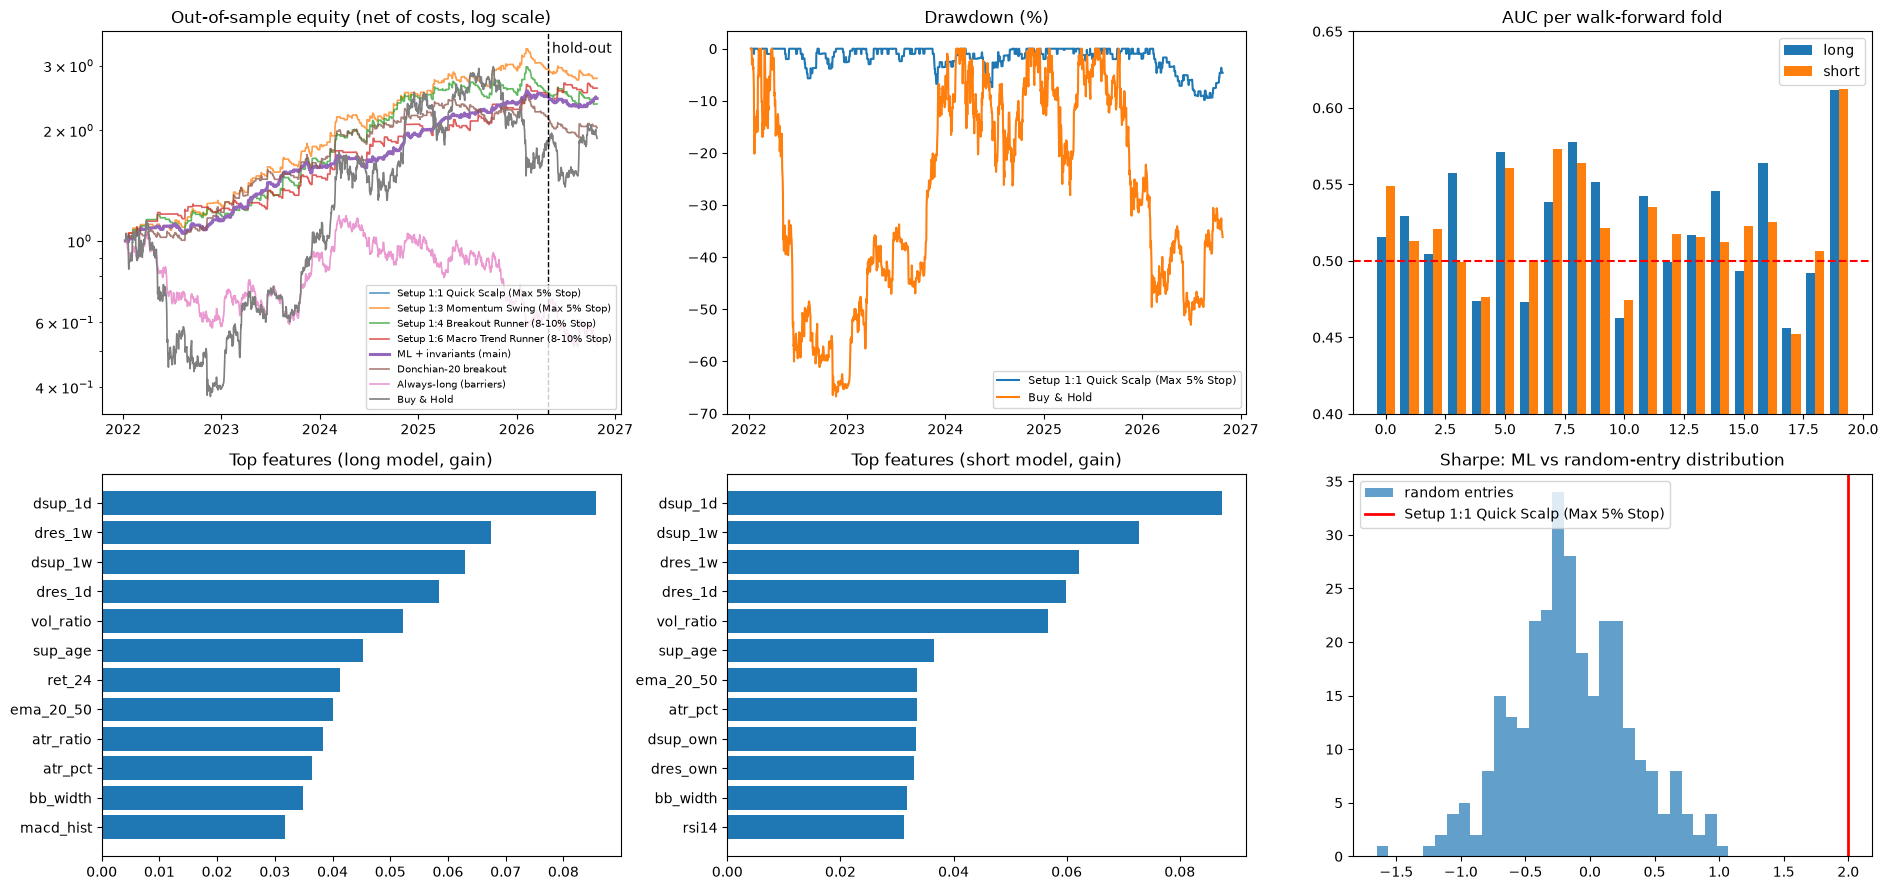

In [18]:
# ---------- plots ----------
fig, ax = plt.subplots(2, 3, figsize=(19, 9))
for name, r in EQ.items():
    eq = (1 + r).cumprod()
    ax[0, 0].plot(eq.index, eq.values, label=name, lw=2.2 if "main" in name else 1.2, alpha=1 if "main" in name or "Hold" in name else .75)
ax[0, 0].axvline(HOLDOUT_START, color="k", ls="--", lw=1); ax[0, 0].text(HOLDOUT_START, ax[0, 0].get_ylim()[1], " hold-out", va="top")
ax[0, 0].set_yscale("log"); ax[0, 0].set_title("Out-of-sample equity (net of costs, log scale)"); ax[0, 0].legend(fontsize=7)

for name in [main, "Buy & Hold"]:
    if name in EQ:
        e = (1 + EQ[name]).cumprod(); ax[0, 1].plot(e.index, (e / e.cummax() - 1).values * 100, label=name)
ax[0, 1].set_title("Drawdown (%)"); ax[0, 1].legend(fontsize=8)

xs = np.arange(len(FOLD_DF)); wd = 0.38
ax[0, 2].bar(xs - wd/2, FOLD_DF.auc_long, wd, label="long"); ax[0, 2].bar(xs + wd/2, FOLD_DF.auc_short, wd, label="short")
ax[0, 2].axhline(0.5, color="r", ls="--"); ax[0, 2].set_ylim(0.4, max(0.65, np.nanmax(FOLD_DF[["auc_long","auc_short"]].values) + .02))
ax[0, 2].set_title("AUC per walk-forward fold"); ax[0, 2].legend()

for lab, imp in (("long", imp_L), ("short", imp_S)):
    g = np.mean([i / i.sum() for i in imp], axis=0)
    top = np.argsort(g)[-12:]
    ax[1, 0 if lab == "long" else 1].barh(np.array(FEATURES)[top], g[top]); ax[1, 0 if lab == "long" else 1].set_title(f"Top features ({lab} model, gain)")

if len(rand_sharpe):
    ax[1, 2].hist(rand_sharpe[~np.isnan(rand_sharpe)], bins=30, alpha=.7, label="random entries")
    ax[1, 2].axvline(ml_all["sharpe"], color="r", lw=2, label=main); ax[1, 2].legend()
ax[1, 2].set_title("Sharpe: ML vs random-entry distribution")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "report.png"), dpi=120); plt.show()


## 14. Verdict

In [19]:
# ---------- honest verdict ----------
g = lambda w, s, k: RES.loc[(w, s), k] if (w, s) in RES.index else np.nan
checks = [
 ("Mean AUC (long & short) > 0.52",                           np.nanmean([FOLD_DF.auc_long.mean(), FOLD_DF.auc_short.mean()]) > 0.52),
 ("OOS Sharpe > Buy & Hold Sharpe",                           g("ALL OOS", main, "sharpe") > g("ALL OOS", "Buy & Hold", "sharpe")),
 ("OOS Sharpe beats 95% of random-entry runs",                bool(p_rand < 0.05) if not np.isnan(p_rand) else False),
 ("Mean R/trade > 0 (bootstrap p < 0.05)",                    bool(p_boot < 0.05) if not np.isnan(p_boot) else False),
 ("ML beats LogReg baseline (OOS Sharpe)",                    g("ALL OOS", main, "sharpe") > (g("ALL OOS", "LogReg Baseline", "sharpe") if ("ALL OOS", "LogReg Baseline") in RES.index else g("ALL OOS", "ML only (no rules)", "sharpe"))),
 ("Sealed hold-out Sharpe > 0",                               g("SEALED HOLD-OUT", main, "sharpe") > 0),
 (f"At least {CFG['min_trades']} OOS trades",                 (g("ALL OOS", main, "trades") or 0) >= CFG["min_trades"]),
]
print(f"VERDICT for {SYMBOL} {TF}")
for t, ok in checks:
    print(("  [PASS] " if ok else "  [FAIL] ") + t)
print(f"\n{sum(ok for _, ok in checks)}/{len(checks)} checks passed.")
print("A strategy is only credible if it passes most checks AND the hold-out; do not re-tune after looking at the hold-out.")


VERDICT for BTCUSDT 4h
  [PASS] Mean AUC (long & short) > 0.52
  [PASS] OOS Sharpe > Buy & Hold Sharpe
  [PASS] OOS Sharpe beats 95% of random-entry runs
  [PASS] Mean R/trade > 0 (bootstrap p < 0.05)
  [FAIL] ML beats LogReg baseline (OOS Sharpe)
  [FAIL] Sealed hold-out Sharpe > 0
  [PASS] At least 40 OOS trades

5/7 checks passed.
A strategy is only credible if it passes most checks AND the hold-out; do not re-tune after looking at the hold-out.


## 15. Final model & latest signal

In [20]:
# ---------- final model (trained on the most recent window) + latest signal ----------
last_t = D.index[-1]
final_model_path = os.path.join(OUT_DIR, f'final_model_{SYMBOL}_{TF}.joblib')
if globals().get('ONLY_ANALYTICS', False) and os.path.exists(final_model_path):
    print(f'>> [ONLY_ANALYTICS=True] Loading saved final model from {final_model_path}...')
    saved_bundle = joblib.load(final_model_path)
    mL_f = saved_bundle['model_long']
    mS_f = saved_bundle['model_short']
    thrL_f = saved_bundle.get('thr_long', 0.5)
    thrS_f = saved_bundle.get('thr_short', 0.5)
    MOVE_MODELS = saved_bundle.get('move_models', {})
    MOVE_TYPICAL = saved_bundle.get('move_typical', {})
else:
    tr_final = np.flatnonzero(D.index >= last_t - pd.DateOffset(months=CFG["train_m"]))
    mL_f, mS_f = fit_side(LGB_PARAMS, tr_final, yL), fit_side(LGB_PARAMS, tr_final, yS)
    thrL_f, thrS_f = yL[tr_final].mean() + EDGE_L, yS[tr_final].mean() + EDGE_S
    MOVE_MODELS, MOVE_TYPICAL = {}, {}
    if RUN_MOVE_MODEL:
        for k in MOVE_TARGETS:
            MOVE_MODELS[k] = fit_move(tr_final, yM[k])
            MOVE_TYPICAL[k] = float(np.average(yM[k][tr_final], weights=Wt[tr_final]))   # "typical" move for context
    joblib.dump(dict(model_long=mL_f, model_short=mS_f, features=FEATURES, thr_long=thrL_f, thr_short=thrS_f,
                     move_models=MOVE_MODELS, move_typical=MOVE_TYPICAL, move_clip=MOVE_CLIP,
                     cfg=CFG, tp_atr=TP_ATR, sl_atr=SL_ATR, horizon=H, tf=TF, trained_until=str(last_t)),
                os.path.join(OUT_DIR, f"final_model_{SYMBOL}_{TF}.joblib"))
    print("Saved final model ->", os.path.join(OUT_DIR, f"final_model_{SYMBOL}_{TF}.joblib"))


x_last = F[FEATURES].iloc[[-1]]
pl_, ps_ = mL_f.predict_proba(x_last)[0, 1], mS_f.predict_proba(x_last)[0, 1]
okL, okS = bool(A["ruleL"].iloc[-1]) or not APPLY_RULES, bool(A["ruleS"].iloc[-1]) or not APPLY_RULES
sig = "LONG" if (pl_ >= thrL_f and okL and (pl_ - thrL_f >= ps_ - thrS_f or not (ps_ >= thrS_f and okS))) else \
      "SHORT" if (ps_ >= thrS_f and okS) else "FLAT"
print(f"Latest closed bar: {T_BAR[-1]}  close={df['close'].iloc[-1]:,.2f}")
print(f"  P(long TP first)={pl_:.3f} (thr {thrL_f:.3f}, rules ok: {okL}) | P(short TP first)={ps_:.3f} (thr {thrS_f:.3f}, rules ok: {okS})  ->  {sig}")
print(f"  If entered: stop = {SL_ATR} x ATR = {SL_ATR*ATR.iloc[-1]:,.2f} | target = {TP_ATR} x ATR = {TP_ATR*ATR.iloc[-1]:,.2f} | time stop = {H} bars")

# ---- expected move for the latest bar ----
EXP = {}
if RUN_MOVE_MODEL:
    a_last = float(ATR.iloc[-1])
    EXP = {k: float(MOVE_MODELS[k].predict(x_last)[0]) for k in MOVE_TARGETS}
    pts = lambda v: v * a_last
    print(f"  Expected move within {H} bars (ATR = {a_last:,.2f}; 'typical' = training-window average):")
    print(f"    best upside   : {EXP['mfe_up']:+.2f} ATR (~{pts(EXP['mfe_up']):+,.0f} pts) | typical {MOVE_TYPICAL['mfe_up']:.2f} ATR")
    print(f"    best downside : {EXP['mfe_dn']:+.2f} ATR (~{-pts(EXP['mfe_dn']):+,.0f} pts) | typical {MOVE_TYPICAL['mfe_dn']:.2f} ATR")
    print(f"    net at bar {H}  : {EXP['net']:+.2f} ATR (~{pts(EXP['net']):+,.0f} pts) | typical {MOVE_TYPICAL['net']:+.2f} ATR")
    side_move = EXP["mfe_up"] if sig == "LONG" else EXP["mfe_dn"] if sig == "SHORT" else None
    if side_move is not None:
        sgn = 1 if sig == "LONG" else -1
        print(f"\n  >> {sig} | P(TP first) = {(pl_ if sig == 'LONG' else ps_):.0%} | expected best move {sgn*pts(side_move):+,.0f} pts ({side_move:.2f} ATR) "
              f"| target {sgn*TP_ATR*a_last:+,.0f} | stop {-sgn*SL_ATR*a_last:+,.0f} | time stop {H} bars")
        print(f"     (expected best move {'>=' if side_move >= TP_ATR else '<'} the {TP_ATR} ATR target -> "
              f"{'room to reach the target' if side_move >= TP_ATR else 'the target looks like a stretch on average'}; this is a peak, not a close.)")


>> [ONLY_ANALYTICS=True] Loading saved final model from D:\Projects_Main\Trade-Pro\Trader-Pro\notebooks\model\4h\final_model_BTCUSDT_4h.joblib...
Latest closed bar: 2026-10-27 00:00:00+00:00  close=79,790.50
  P(long TP first)=0.347 (thr 0.854, rules ok: True) | P(short TP first)=0.653 (thr 0.619, rules ok: True)  ->  SHORT
  If entered: stop = 1.0 x ATR = 775.69 | target = 3.0 x ATR = 2,327.06 | time stop = 6 bars
  Expected move within 6 bars (ATR = 775.69; 'typical' = training-window average):
    best upside   : +1.54 ATR (~+1,194 pts) | typical 1.35 ATR
    best downside : +1.54 ATR (~-1,192 pts) | typical 1.37 ATR
    net at bar 6  : +0.47 ATR (~+361 pts) | typical +0.04 ATR

  >> SHORT | P(TP first) = 65% | expected best move -1,192 pts (1.54 ATR) | target -2,327 | stop +776 | time stop 6 bars
     (expected best move < the 3.0 ATR target -> the target looks like a stretch on average; this is a peak, not a close.)


## 16. Save model + metadata to Google Drive (and verify)

In [21]:
# ---------- save everything to Drive / Local and verify ----------
import datetime, shutil

# 1. Versioned model copy
stamp = datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M")
main_path = os.path.join(OUT_DIR, f"final_model_{SYMBOL}_{TF}.joblib")
if SAVE_VERSIONED and os.path.exists(main_path):
    shutil.copy2(main_path, os.path.join(OUT_DIR, f"final_model_{SYMBOL}_{TF}_{stamp}.joblib"))

# 2. Save model card metadata
def _num(x):
    x = float(x)
    return None if math.isnan(x) else round(x, 5)

card = dict(symbol=SYMBOL, tf=TF, saved_utc=stamp, trained_until=str(last_t), horizon_bars=H, tp_atr=TP_ATR, sl_atr=SL_ATR,
            n_features=len(FEATURES), features=FEATURES, dropped_features=DROP_FEATURES,
            lgb_params=LGB_PARAMS, edge_long=_num(EDGE_L), edge_short=_num(EDGE_S),
            thr_long=_num(thrL_f), thr_short=_num(thrS_f),
            mean_auc_long=_num(FOLD_DF.auc_long.mean()), mean_auc_short=_num(FOLD_DF.auc_short.mean()),
            verdict=[dict(check=t, passed=bool(ok)) for t, ok in checks],
            latest_signal=dict(signal=sig, p_long=_num(pl_), p_short=_num(ps_), bar=str(T_BAR[-1])),
            expected_move=(dict(unit="ATR", up=_num(EXP["mfe_up"]), down=_num(EXP["mfe_dn"]), net=_num(EXP["net"]),
                                typical={k: _num(v) for k, v in MOVE_TYPICAL.items()},
                                oos_spearman={k: _num(MV_DF[MV_DF.target == k].spearman.mean()) for k in MOVE_TARGETS},
                                oos_r2_vs_mean={k: _num(MV_DF[MV_DF.target == k].r2_vs_mean.mean()) for k in MOVE_TARGETS})
                           if (globals().get('RUN_MOVE_MODEL', False) and 'EXP' in globals()) else None))
json.dump(card, open(os.path.join(OUT_DIR, "model_card.json"), "w"), indent=1, default=str)

# 3. COMPULSORY GOOGLE DRIVE SYNC / UPLOAD
DRIVE_BACKUP_ROOT = "/content/drive/MyDrive/crypto_models"
if os.path.exists("/content/drive/MyDrive"):
    drive_target = os.path.join(DRIVE_BACKUP_ROOT, TF)
    os.makedirs(drive_target, exist_ok=True)
    for fname in os.listdir(OUT_DIR):
        src_f = os.path.join(OUT_DIR, fname)
        if os.path.isfile(src_f):
            shutil.copy2(src_f, os.path.join(drive_target, fname))
    print(f">> [COMPULSORY DRIVE SYNC] Successfully synced all model artifacts to Google Drive: {drive_target}")
    try:
        from google.colab import drive
        drive.flush_and_unmount()
        print(">> Google Drive flushed successfully.")
    except Exception:
        pass
else:
    print(f">> Models saved locally in: {OUT_DIR}")
    print(">> Note: If training in Google Colab, mount Google Drive in Cell 3 to sync automatically.")

print("\nArtifacts in", OUT_DIR)
for fn in sorted(os.listdir(OUT_DIR)):
    p = os.path.join(OUT_DIR, fn)
    print(f"  {fn:55s} {os.path.getsize(p)/1024:10.1f} KB")


>> Models saved locally in: D:\Projects_Main\Trade-Pro\Trader-Pro\notebooks\model\4h
>> Note: If training in Google Colab, mount Google Drive in Cell 3 to sync automatically.

Artifacts in D:\Projects_Main\Trade-Pro\Trader-Pro\notebooks\model\4h
  benchmark_metrics.csv                                          5.6 KB
  best_params.json                                               0.4 KB
  final_model_BTCUSDT_4h.joblib                                873.9 KB
  final_model_BTCUSDT_4h_20261026_1612.joblib                 1276.5 KB
  final_model_BTCUSDT_4h_20261027_0633.joblib                  873.9 KB
  final_model_BTCUSDT_4h_20261027_0643.joblib                  873.9 KB
  final_model_BTCUSDT_4h_20261027_0856.joblib                  873.9 KB
  final_model_BTCUSDT_4h_20261027_0900.joblib                  873.9 KB
  final_model_BTCUSDT_4h_20261027_0915.joblib                  873.9 KB
  final_model_BTCUSDT_4h_20261027_0931.joblib                  873.9 KB
  final_model_BTCUSDT_4h_20261027_